# Outlier appendix: the one look on month 5

Our model learns from the simulator's answer key, which marks every mule. A real bank only knows the mules its rules
alerted and its investigators confirmed: 189 of 732 in the whole window. This appendix asks three questions
(plan: `outputs/modelling/outlier/PLAN.md`):

1. **No labels:** can a detector that never sees a label beat the bank's rules at the rules' own weekly budget?
2. **Hidden mules:** of the mules the bank never confirmed, how many does each method find?
3. **Bank labels:** how much does our supervised model lose when it learns from the bank's confirmed mules only?

| # | Method | Learns from |
|---|---|---|
| M0 | the bank's rules R1–R6 | none (the benchmark) |
| M1 | `frozen_tuned`, the model of record (38 inputs) | the simulator's truth |
| M1b | `truth_macos`: M1's recipe retrained on this Mac, M2's yardstick | the simulator's truth |
| M2 | `bank_label`: the same recipe on the bank's confirmed mules only | the bank's labels |
| M3 | `rarity`: per input, how rare the value is in its suspicious direction; mean of the 3 rarest | none |
| M3s | `rarity_sum`: the same rarities summed over all 19 inputs (ECOD's sum); side by side only, never used to choose | none |
| M4 | `iforest`: Isolation Forest on the 19 inputs' ranks | none |

Every method flags at the rules' weekly budget (124 flags on the month-5 cohort over weeks 0–26), and a flag is
permanent. The settings were frozen and committed (31 Oct 2026, 18:24, PR #49) **before** month 5 was scored. The one
look ran on 31 Oct 2026, 19:03, on that commit (`python -m evaluation.outlier_look look`).

**This notebook reads only the look's committed outputs** in `outputs/modelling/outlier/v1_full/`. It reads no data
folder and no label, so running it again is not a new look. It writes `report.md`, two figures and a few CSVs to the
same folder (or to `EDA_REPORT` if set).

## 0. Setup and provenance

In [1]:
from __future__ import annotations
import json, os, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# find the repo root so Run All works from notebooks/
ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)

LOOK = Path("outputs/modelling/outlier/v1_full")            # the one look's committed outputs (read only)
REPORT = Path(os.environ.get("EDA_REPORT", LOOK))           # report.md, figures and CSVs go here
REPORT.mkdir(parents=True, exist_ok=True)
DRY = Path("outputs/modelling/results/v1_full/month5_dryrun_v2")   # the model of record's earlier month-5 run
H = 26                                                      # horizon: weeks 0-26
METHODS = {"frozen_tuned": "M1 frozen model (truth)", "truth_macos": "M1b same recipe, this Mac (truth)",
           "bank_label": "M2 bank labels", "rarity": "M3 rarity, mean of 3 (no labels)",
           "rarity_sum": "M3s rarity sum, side by side (no labels)", "iforest": "M4 Isolation Forest (no labels)"}
LABEL = {"rules": "M0 rules R1-R6", **METHODS}
ALL = ["rules", *METHODS]
show = display if "ipykernel" in sys.modules else print
T0 = time.time()

Check that every file comes from the one look: each method's harness run scored the score file named in `LOOK.json`
(same sha256), all on the committed commit of `LOOK_STARTED.json` with no uncommitted changes; and that the model of
record catches the same number as its earlier month-5 run on the same data.

In [2]:
look = json.loads((LOOK / "LOOK.json").read_text())
started = json.loads((LOOK / "LOOK_STARTED.json").read_text())
frozen = json.loads((LOOK / "settings.json").read_text())
hm = json.loads((LOOK / "hidden_mules_settings.json").read_text())
SET = {m: json.loads((LOOK / m / "settings.json").read_text()) for m in METHODS}
for m in METHODS:
    assert SET[m]["scores_sha256"] == look["scores"][m]["sha256"] == hm["scores"][m]["sha256"], m
    assert SET[m]["git_commit"] == started["git_commit"] and not SET[m]["git_uncommitted_changes"], m
    assert SET[m]["run_manifest_sha256"] == hm["run_manifest_sha256"], m
assert hm["git_commit"] == started["git_commit"] and not hm["git_uncommitted_changes"]

dry_set = json.loads((DRY / "settings.json").read_text())
dry_caught = int(pd.read_csv(DRY / f"summary_w{H}.csv").set_index("policy").loc["model", "caught"])
RUN_HASH = hm["run_manifest_sha256"]
print(f"settings frozen {frozen['frozen']} (code {frozen['git_commit'][:7]}); look started {started['started']}, "
      f"done {look['done']}, code {started['git_commit'][:7]}")
print(f"data {hm['data']}, run_manifest sha256 {RUN_HASH[:6]}...; month {hm['cohort_months']}, weeks 0-{hm['horizon']}, "
      f"{hm['mules']} mules, budget {hm['budget']} flags")
print(f"month5_dryrun_v2: same data {dry_set['run_manifest_sha256'] == RUN_HASH}, model of record caught {dry_caught}")

settings frozen 2026-10-31 18:24 (code 2d0f91f); look started 2026-10-31 19:03, done 2026-10-31 19:04, code 39119ed
data data/v1_full, run_manifest sha256 4ce1c4...; month [5], weeks 0-26, 78 mules, budget 124 flags
month5_dryrun_v2: same data True, model of record caught 63


## 1. The main table

One row per method, all on the same 29,120 accounts opened in month 5 and the same 78 mules (mule by the end of week
26). `caught`: mules flagged by week 26. `recall_final_label`: caught over all 97 launderers of the cohort (the ones
who start after week 26 count as missed). `median_days_from_start`: days from the laundering start to the first flag
(fake accounts count from opening). Head to head with the rules: mules caught by both, by the method only, by the
rules only.

The per-mule tables (`<method>/launderers.csv`) rebuild every count of the summaries exactly; the checks below
assert it, and later sections use them.

In [3]:
SUM = {m: pd.read_csv(LOOK / m / f"summary_w{H}.csv").set_index("policy") for m in METHODS}
LAU = {m: pd.read_csv(LOOK / m / "launderers.csv").set_index("account_id") for m in METHODS}
base = LAU["frozen_tuned"]
FIXED = ["profile", "start_week", "closed_week", "rules_first_alert_week"]
MULES = base.index[(base.profile == "fake") | (base.start_week <= H)]      # mules by the end of week 26
CONFIRMED = set(MULES[base.loc[MULES, "closed_week"].notna()])           # closed by the bank = confirmed (D2)
FLAG = {"rules": base.loc[MULES, "rules_first_alert_week"].where(lambda s: s <= H)}
for m, d in LAU.items():
    assert d.index.equals(base.index) and d[FIXED].equals(base[FIXED]), m
    assert SUM[m].loc["rules"].equals(SUM["frozen_tuned"].loc["rules"]), m
    FLAG[m] = d.loc[MULES, "model_flag_week_w26"]
CAUGHT = {m: set(s.index[s.notna()]) for m, s in FLAG.items()}
for m in METHODS:
    assert len(CAUGHT[m]) == SUM[m].loc["model", "caught"] and len(CAUGHT["rules"]) == SUM[m].loc["rules", "caught"]
assert len(MULES) == hm["mules"]

COLS = ["flagged", "caught", "precision", "recall_final_label", "median_days_from_start", "flagged_before_start",
        "caught_fake", "caught_witting", "caught_unwitting"]
MAIN = pd.DataFrame({"rules": SUM["frozen_tuned"].loc["rules", COLS],
                     **{m: SUM[m].loc["model", COLS] for m in METHODS}}).T
H2H = pd.DataFrame({m: SET[m]["head_to_head"][str(H)] for m in METHODS}).T
MAIN = MAIN.join(H2H[["both", "model_only", "rules_only"]].astype("Int64"))
MAIN.insert(0, "method", [LABEL[m] for m in MAIN.index])
for c in ("precision", "recall_final_label"):
    MAIN[c] = MAIN[c].astype(float).round(3)
print(f"{len(MULES)} mules by week {H}; {len(CONFIRMED)} of them confirmed by the bank at some point in the window")
show(MAIN)

78 mules by week 26; 16 of them confirmed by the bank at some point in the window


,method,flagged,caught,precision,recall_final_label,median_days_from_start,flagged_before_start,caught_fake,caught_witting,caught_unwitting,both,model_only,rules_only
rules,M0 rules R1-R6,119,16,0.134,0.165,8.5,0,13/70,3/5,0/3,<NA>,<NA>,<NA>
frozen_tuned,M1 frozen model (truth),124,63,0.508,0.649,8.0,0,59/70,3/5,1/3,14,49,2
truth_macos,"M1b same recipe, this Mac (truth)",124,63,0.508,0.649,10.0,0,59/70,3/5,1/3,14,49,2
bank_label,M2 bank labels,124,54,0.435,0.557,9.0,2,50/70,3/5,1/3,13,41,3
rarity,"M3 rarity, mean of 3 (no labels)",124,16,0.129,0.165,9.0,0,14/70,2/5,0/3,4,12,12
rarity_sum,"M3s rarity sum, side by side (no labels)",124,39,0.315,0.402,8.0,0,34/70,4/5,1/3,10,29,6
iforest,M4 Isolation Forest (no labels),124,16,0.129,0.165,12.5,0,15/70,1/5,0/3,4,12,12


## 2. How sure are we? Paired differences against the rules

With 78 mules a few accounts are noise. The look resampled the cohort's accounts 1,000 times (`bootstrap.csv`). A
method **beats** another only if the 95% interval of the paired difference in mules caught excludes 0 (the rule
fixed in the plan).

In [4]:
BOOT = pd.read_csv(LOOK / "bootstrap.csv")


def pair(a, b):
    """a minus b in mules caught, with its 95% interval (bootstrap.csv stores each pair once, in either order)."""
    r = BOOT[(BOOT.a == a) & (BOOT.b == b)]
    if len(r):
        r = r.iloc[0]
        return {"difference": r.difference, "low_95": r.low_95, "high_95": r.high_95, "clear": bool(r.clear)}
    r = BOOT[(BOOT.a == b) & (BOOT.b == a)].iloc[0]
    return {"difference": -r.difference, "low_95": -r.high_95, "high_95": -r.low_95, "clear": bool(r.clear)}


def beats(a, b):
    p = pair(a, b)
    return p["clear"] and p["difference"] > 0


VS_RULES = pd.DataFrame({m: pair(m, "rules") for m in METHODS}).T
for m in METHODS:
    assert VS_RULES.loc[m, "difference"] == len(CAUGHT[m]) - len(CAUGHT["rules"])
PAIRS = pd.DataFrame({f"{a} - {b}": pair(a, b) for a, b in
                      [("bank_label", "truth_macos"), ("truth_macos", "frozen_tuned"), ("rarity", "iforest"),
                       ("rarity_sum", "rarity"), ("rarity_sum", "iforest"), ("bank_label", "rarity_sum")]}).T
show(VS_RULES.rename(index=LABEL))
show(PAIRS)

,difference,low_95,high_95,clear
M1 frozen model (truth),47,37.0,56.0,True
"M1b same recipe, this Mac (truth)",47,37.0,56.0,True
M2 bank labels,38,27.975,49.0,True
"M3 rarity, mean of 3 (no labels)",0,-11.0,10.0,False
"M3s rarity sum, side by side (no labels)",23,12.0,33.0,True
M4 Isolation Forest (no labels),0,-10.0,10.0,False


,difference,low_95,high_95,clear
bank_label - truth_macos,-9,-16.0,-2.0,True
truth_macos - frozen_tuned,0,-4.0,4.0,False
rarity - iforest,0,-10.0,9.0,False
rarity_sum - rarity,23,15.0,32.0,True
rarity_sum - iforest,23,14.0,32.0,True
bank_label - rarity_sum,15,5.0,25.0,True


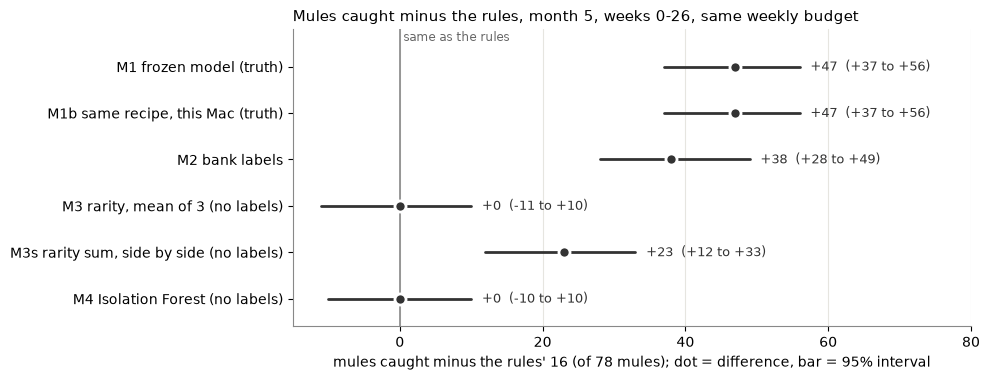

In [5]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e5e0", "grid.linewidth": 0.8, "axes.edgecolor": "#888", "font.size": 10})
INK = "#333333"
order = list(METHODS)[::-1]
fig1, ax = plt.subplots(figsize=(10, 3.9))
for i, m in enumerate(order):
    r = VS_RULES.loc[m]
    ax.plot([r.low_95, r.high_95], [i, i], color=INK, lw=2, solid_capstyle="round")
    ax.plot(r.difference, i, "o", ms=8, color=INK, mec="white", mew=2, zorder=3)
    ax.text(r.high_95 + 1.5, i, f"{r.difference:+.0f}  ({r.low_95:+.0f} to {r.high_95:+.0f})", va="center",
            fontsize=9, color=INK)
ax.axvline(0, color="#888", lw=1.2)
ax.text(0.5, len(order) - 0.45, "same as the rules", fontsize=8.5, color="#666")
ax.set_yticks(range(len(order)), [METHODS[m] for m in order])
ax.set_ylim(-0.6, len(order) - 0.2)
ax.set_xlim(-15, 80)
ax.grid(axis="y", visible=False)
ax.set_xlabel(f"mules caught minus the rules' {len(CAUGHT['rules'])} (of {len(MULES)} mules); dot = difference, "
              "bar = 95% interval")
ax.set_title("Mules caught minus the rules, month 5, weeks 0-26, same weekly budget",
             loc="left", fontsize=10.5)
fig1.tight_layout()
fig1.savefig(REPORT / "01_vs_rules.png", dpi=150)
plt.show()

## 3. When each method catches

Mules caught by the end of each week since opening (a flag is permanent), against the number of mules that have
started laundering by then. Fake accounts count as mules from opening but launder only from their start, so the
started line is the useful ceiling for early weeks. M1b is left out: it ends at the same 63 as M1 (median 10 days
from start vs 8).

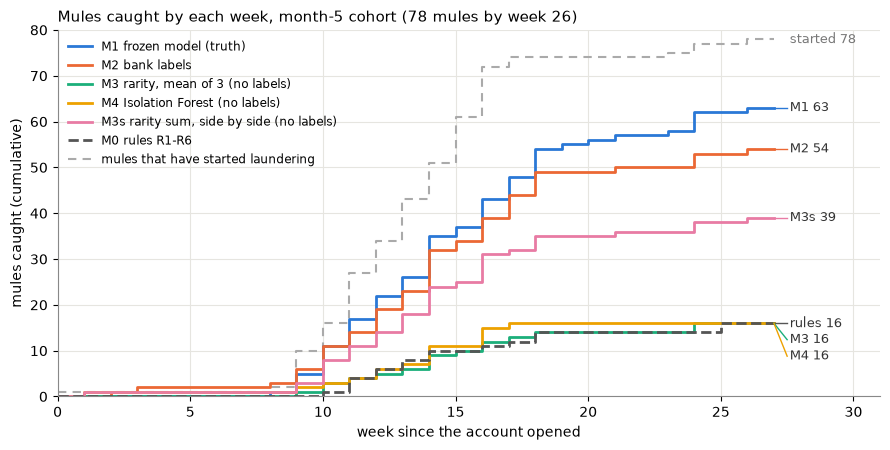

In [6]:
WEEKS = range(H + 1)
CUM = pd.DataFrame({m: [(FLAG[m] <= w).sum() for w in WEEKS] for m in ALL}, index=pd.Index(WEEKS, name="week"))
CUM["started"] = [(base.loc[MULES, "start_week"] <= w).sum() for w in WEEKS]
for m in ALL:
    assert CUM.loc[H, m] == len(CAUGHT[m])
COLORS = {"frozen_tuned": "#2a78d6", "bank_label": "#eb6834", "rarity": "#1baf7a", "iforest": "#eda100",
          "rarity_sum": "#e87ba4", "rules": "#555555"}                    # validated categorical order
SHORT = {"frozen_tuned": "M1", "bank_label": "M2", "rarity": "M3", "iforest": "M4", "rarity_sum": "M3s",
         "rules": "rules"}

fig2, ax = plt.subplots(figsize=(9, 4.6))
X = [*CUM.index, H + 1]                                   # draw the last week to its end
ax.step(X, [*CUM["started"], CUM.loc[H, "started"]], where="post", color="#aaaaaa", lw=1.5, ls=(0, (4, 3)))
for m in COLORS:
    ax.step(X, [*CUM[m], CUM.loc[H, m]], where="post", color=COLORS[m], lw=2, ls="--" if m == "rules" else "-")
# direct labels at the right end, spaced so equal end values (16, 16, 16) do not overlap
ends = sorted(((CUM.loc[H, m], m) for m in COLORS), reverse=True)
y_prev = None
for v, m in ends:
    y = v if y_prev is None else min(v, y_prev - 3.6)
    ax.text(H + 1.6, y, f"{SHORT[m]} {v}", va="center", fontsize=9, color=INK)
    ax.plot([H + 1, H + 1.5], [v, y], color=COLORS[m], lw=1)
    y_prev = y
ax.text(H + 1.6, CUM.loc[H, "started"], f"started {CUM.loc[H, 'started']}", va="center", fontsize=9, color="#777")
ax.set_xlim(0, H + 5)
ax.set_ylim(0, len(MULES) + 2)
ax.set_xlabel("week since the account opened")
ax.set_ylabel("mules caught (cumulative)")
ax.legend([Line2D([], [], color=COLORS[m], lw=2, ls="--" if m == "rules" else "-") for m in COLORS] +
          [Line2D([], [], color="#aaaaaa", lw=1.5, ls=(0, (4, 3)))],
          [METHODS.get(m, LABEL[m]) for m in COLORS] + ["mules that have started laundering"],
          loc="upper left", fontsize=8.5, frameon=False)
ax.set_title(f"Mules caught by each week, month-5 cohort ({len(MULES)} mules by week {H})", loc="left", fontsize=11)
fig2.tight_layout()
fig2.savefig(REPORT / "02_caught_by_week.png", dpi=150)
plt.show()

## 4. Hidden mules: confirmed by the bank vs never confirmed

"Confirmed" = the bank closed the account at some point in the window (decision D2); the simulator closes only after a
confirmed alert. The rules found the confirmed ones by construction, so they catch few of the others. The type table
splits the same catches by the hidden mule type (fake account, witting or unwitting real customer).

In [7]:
GROUPS = {"never confirmed": set(MULES) - CONFIRMED, "bank confirmed": CONFIRMED}
HID = pd.DataFrame({g: {"mules": len(s), **{m: len(CAUGHT[m] & s) for m in ALL}} for g, s in GROUPS.items()}).T
hc = pd.read_csv(LOOK / "hidden.csv").set_index("group").rename(index=lambda g: g.replace("_", " "))
assert HID.equals(hc.loc[HID.index, HID.columns].astype(HID.dtypes.iloc[0]))
TYPE = pd.read_csv(LOOK / "type.csv").set_index("group")
show(HID)
show(TYPE)

,mules,rules,frozen_tuned,truth_macos,bank_label,rarity,rarity_sum,iforest
never confirmed,62,3,50,50,42,12,30,13
bank confirmed,16,13,13,13,12,4,9,3


,mules,rules,frozen_tuned,truth_macos,bank_label,rarity,rarity_sum,iforest
group,,,,,,,,
fake,70,13,59,59,50,14,34,15
witting,5,3,3,3,3,2,4,1
unwitting,3,0,1,1,1,0,1,0


## 5. Who catches whom

Row method catches, column method misses: how many mules. A method that adds mules others miss is a candidate for
combining. Note: two methods' flags together use **twice** the rules' budget, so a union is not a fair comparison
with one method; it only shows how different their catches are.

In [8]:
MISS = pd.DataFrame({b: {a: len(CAUGHT[a] - CAUGHT[b]) for a in ALL} for b in ALL})
LABEL_FREE = CAUGHT["rarity"] | CAUGHT["iforest"]
OVER = {
    "rarity and iforest both": len(CAUGHT["rarity"] & CAUGHT["iforest"]),
    "rarity or iforest": len(LABEL_FREE),
    "rarity or iforest, missed by bank_label": len(LABEL_FREE - CAUGHT["bank_label"]),
    "  of them never confirmed": len(LABEL_FREE - CAUGHT["bank_label"] - CONFIRMED),
    "rarity or iforest, missed by frozen_tuned": len(LABEL_FREE - CAUGHT["frozen_tuned"]),
    "rules or rarity": len(CAUGHT["rules"] | CAUGHT["rarity"]),
    "rules or iforest": len(CAUGHT["rules"] | CAUGHT["iforest"]),
    "rules or bank_label": len(CAUGHT["rules"] | CAUGHT["bank_label"]),
}
assert OVER["rules or rarity"] == SET["rarity"]["head_to_head"][str(H)]["either"]
show(MISS)
show(pd.Series(OVER, name="mules"))

,rules,frozen_tuned,truth_macos,bank_label,rarity,rarity_sum,iforest
rules,0,2,2,3,12,6,12
frozen_tuned,49,0,2,10,49,29,50
truth_macos,49,2,0,11,49,28,49
bank_label,41,1,2,0,40,21,44
rarity,12,2,2,2,0,1,12
rarity_sum,29,5,4,6,24,0,26
iforest,12,3,2,6,12,3,0


rarity and iforest both                       4
rarity or iforest                            28
rarity or iforest, missed by bank_label       8
  of them never confirmed                     5
rarity or iforest, missed by frozen_tuned     5
rules or rarity                              28
rules or iforest                             28
rules or bank_label                          57
Name: mules, dtype: int64

## 6. By laundering pattern

Mules caught per main SAML-D laundering pattern (as written by the look; the pattern is hidden from every method).
This shows which shapes each method sees: the cheap version of a held-out-pattern test.

In [9]:
PATTERN = pd.read_csv(LOOK / "pattern.csv").set_index("group")
assert PATTERN["mules"].sum() == len(MULES)
show(PATTERN)

,mules,rules,frozen_tuned,truth_macos,bank_label,rarity,rarity_sum,iforest
group,,,,,,,,
Structuring,28,4,23,24,21,12,22,8
Deposit-Send,12,2,9,9,6,0,5,5
Behavioural_Change_1,6,0,3,3,2,0,1,0
Behavioural_Change_2,6,1,4,5,4,0,1,0
Fan_In,5,3,5,5,5,2,2,1
Gather-Scatter,5,2,5,5,4,0,2,1
Cycle,3,1,3,2,2,1,2,0
Fan_Out,3,2,3,3,3,0,1,0
Layered_Fan_In,3,0,2,2,2,0,1,0


## 7. Top false alarms: what "unusual but innocent" looks like

The 20 highest-scored normal accounts per method, at the week they were flagged (`alarms.csv`), described by the
median of each of the 19 outlier inputs. Shares run 0–1; `n_payers_*` and `n_payees_wk` are counts;
`med_in_out_minutes_wk` is minutes from money in to money out; `peer_ratio_money_in` is money in over the median of
accounts of the same age; `self_vs_past_*` compare this week with the account's own earlier weeks.

In [10]:
ALARMS = pd.read_csv(LOOK / "alarms.csv")
INPUTS = frozen["outlier"]["inputs"]
assert ALARMS.groupby("method").size().reindex(list(METHODS)).eq(20).all()
FA = ALARMS.groupby("method")[INPUTS].median().T[list(METHODS)]
FA.loc["weeks_since_open"] = ALARMS.groupby("method")["weeks_since_open"].median()
show(FA.round(2))

method,frozen_tuned,truth_macos,bank_label,rarity,rarity_sum,iforest
passthrough_wk,1.00,1.00,1.00,1.00,1.00,1.00
out_1h_share_wk,0.31,0.26,0.13,0.33,0.45,0.28
out_24h_share_wk,0.80,0.70,0.48,2.49,2.37,0.73
med_in_out_minutes_wk,3359.22,4593.27,3844.49,497.18,622.75,1434.47
n_payers_wk,1.00,1.00,1.00,12.00,10.00,2.00
n_payees_wk,4.00,4.00,4.00,4.00,5.00,4.50
new_payer_share_wk,1.00,1.00,0.71,1.00,1.00,1.00
self_vs_past_money_in,1.87,1.20,1.42,3.44,4.89,19.53
self_vs_past_payers,1.00,0.50,1.00,14.00,11.00,1.00
self_vs_past_rows,1.00,1.00,1.20,11.00,10.00,2.00


## 8. Against the reading written before the look

The plan's table "How to read the result" was written on 30 Oct 2026, before month 5 was scored. Each row is judged
with the bootstrap rule of section 2. "Close" and "far" were not given a number in advance, so for M2 the table reports
whether the interval includes 0 and the size of the gap; the reading is in the interpretation below.

In [11]:
p21 = pair("bank_label", "truth_macos")
hidden_extra = OVER["  of them never confirmed"]
READ = pd.DataFrame([
    {"pre-written result": "M3/M4 > M0", "holds": beats("rarity", "rules") or beats("iforest", "rules"),
     "evidence": f"rarity {VS_RULES.loc['rarity', 'difference']:+.0f} ({VS_RULES.loc['rarity', 'low_95']:+.0f} to "
                 f"{VS_RULES.loc['rarity', 'high_95']:+.0f}), iforest {VS_RULES.loc['iforest', 'difference']:+.0f} "
                 f"({VS_RULES.loc['iforest', 'low_95']:+.0f} to {VS_RULES.loc['iforest', 'high_95']:+.0f}) vs the rules"},
    {"pre-written result": "M3/M4 = M0 or below",
     "holds": not (beats("rarity", "rules") or beats("iforest", "rules")),
     "evidence": "neither interval excludes 0"},
    {"pre-written result": "M2 close to M1b", "holds": not p21["clear"],
     "evidence": f"M2 {len(CAUGHT['bank_label'])} vs M1b {len(CAUGHT['truth_macos'])}: {p21['difference']:+.0f} "
                 f"({p21['low_95']:+.0f} to {p21['high_95']:+.0f}); keeps "
                 f"{len(CAUGHT['bank_label']) / len(CAUGHT['truth_macos']):.0%} of M1b's catches"},
    {"pre-written result": "M2 far below M1b", "holds": "judgment",
     "evidence": f"a clear loss of {-p21['difference']:.0f}, but {VS_RULES.loc['bank_label', 'difference']:+.0f} "
                 "vs the rules"},
    {"pre-written result": "M3/M4 catch hidden mules that M2 misses", "holds": hidden_extra > 0,
     "evidence": f"{hidden_extra} never-confirmed mules (of {OVER['rarity or iforest, missed by bank_label']} missed "
                 "by M2), with two methods' flags = twice the budget"},
])
show(READ)

,pre-written result,holds,evidence
0,M3/M4 > M0,False,"rarity +0 (-11 to +10), iforest +0 (-10 to +10..."
1,M3/M4 = M0 or below,True,neither interval excludes 0
2,M2 close to M1b,False,M2 54 vs M1b 63: -9 (-16 to -2); keeps 86% of ...
3,M2 far below M1b,judgment,"a clear loss of 9, but +38 vs the rules"
4,M3/M4 catch hidden mules that M2 misses,True,"5 never-confirmed mules (of 8 missed by M2), w..."


## 9. Interpretation and the report

The interpretation was written after the run (31 Oct 2026). Every number it quotes is asserted against the tables
above, so a change in the files would stop this cell.

In [12]:
c = {m: len(CAUGHT[m]) for m in ALL}
never = HID.loc["never confirmed"]
assert (c["rules"], c["frozen_tuned"], c["truth_macos"], c["bank_label"], c["rarity"], c["rarity_sum"], c["iforest"]) \
    == (16, 63, 63, 54, 16, 39, 16)
assert (never["mules"], never["rules"], never["frozen_tuned"], never["bank_label"], never["rarity"],
        never["iforest"], never["rarity_sum"]) == (62, 3, 50, 42, 12, 13, 30)
assert (OVER["rarity and iforest both"], OVER["rules or rarity"], OVER["rules or iforest"]) == (4, 28, 28)
assert (OVER["rarity or iforest, missed by bank_label"], hidden_extra) == (8, 5)
assert tuple(PAIRS.loc["rarity_sum - rarity", ["difference", "low_95", "high_95"]]) == (23, 15, 32)
assert tuple(VS_RULES.loc["bank_label", ["difference", "low_95"]].astype(float).round()) == (38, 28)
assert (PATTERN.loc["Structuring", ["rarity", "rarity_sum"]].tolist(), PATTERN.loc["Deposit-Send", "rarity"]) \
    == ([12, 22], 0)
assert (MAIN.loc["iforest", "median_days_from_start"], MAIN.loc["rules", "median_days_from_start"]) == (12.5, 8.5)
assert sorted(MAIN.loc[[m for m in ALL if m != "iforest"], "median_days_from_start"].astype(float)) == [8, 8, 8.5, 9, 9, 10]
assert (H2H.loc["rarity", "both"], H2H.loc["iforest", "both"]) == (4, 4)
assert tuple(VS_RULES.loc["rarity", ["low_95", "high_95"]]) == (-11, 10)
assert (len(CAUGHT["bank_label"] - CONFIRMED), TYPE.loc["fake", "bank_label"]) == (42, 50)
assert (FA.loc["n_payers_wk", ["rarity", "rarity_sum"]].tolist(), FA.loc["self_vs_past_payers", ["rarity", "rarity_sum"]].tolist()) \
    == ([12, 10], [14, 11])
assert 480 <= FA.loc["med_in_out_minutes_wk", ["rarity", "rarity_sum"]].min() <= FA.loc["med_in_out_minutes_wk", ["rarity", "rarity_sum"]].max() <= 630
assert FA.loc["weeks_since_open", ["frozen_tuned", "truth_macos", "bank_label", "iforest"]].tolist() == [19.5, 20, 3.5, 3]
assert round(FA.loc["peer_ratio_money_in", "bank_label"]) == 30 and round(FA.loc["self_vs_past_money_in", "iforest"]) == 20
assert dry_caught == c["frozen_tuned"] and dry_set["run_manifest_sha256"] == RUN_HASH

INTERPRETATION = r"""
One month, 78 mules: every count below moves by about ±10 between resamples, so only the differences whose
interval excludes 0 count as results.

**1. No labels: the pre-chosen detectors tie the rules.** Rarity (M3) and Isolation Forest (M4) each catch 16 of 78,
the same as the rules (difference 0; 95% interval −11 to +10 and −10 to +10). By the table written before the look,
outlier detection alone is not enough here: our supervised result depends on labels. They are also not just the rules
again. Each shares only 4 of its 16 catches with the rules, so the rules and rarity together catch 28 (at twice the
budget). Isolation Forest catches later than every other method (median 12.5 days after the start vs 8–10).

**2. The aggregation matters more than the method.** ECOD's own sum over all 19 inputs (M3s) catches 39: 23 more than
the rules (12 to 33) and 23 more than the pre-chosen mean of the 3 rarest (15 to 32). The gap is mostly two patterns:
Structuring (22 of 28 vs 12) and Deposit-Send (5 of 12 vs 0). A plausible reason, not checked: these bursts are
moderately unusual on many inputs at once, which a sum adds up and a top-3 mean ignores. The review of 30 Oct chose
the top-3 mean because a sum favours busy ordinary accounts; on this look that choice was the worse one. M3s was fixed
in advance as a side-by-side comparison, never used to choose, so we report it as a finding to confirm on fresh data,
not as the appendix's answer.

**3. Bank labels: a clear but moderate loss.** Trained only on the mules the bank confirmed, M2 catches 54 vs 63 for
the same recipe on the truth (M1b): 9 fewer (2 to 16), 86% of the catches kept, and still 38 more than the rules
(28 to 49). Of the 62 mules the bank never confirmed, M2 catches 42 (M1b 50, rules 3). The 30 Oct review warned that
bank labels teach "find the rules' mules, earlier", because every confirmed mule was first alerted by the rules. The
result says M2 learns more than that: most of its catches are mules the rules never confirmed, mostly fake accounts
(50 of 70), which look alike whether or not the bank caught them. Read against the pre-written table: the main result
survives realistic labels, but it is a best case by about 9 of 63 catches, and the report should state that cost as
a limitation.

**4. Hidden mules.** The rules catch 3 of the 62 never-confirmed mules, by construction: the bank's confirmations come
from the rules' own alerts. The model of record catches 50 of them. This is the plainest way to show what the bank's
labels miss.

**5. Labels and outliers find some different mules, but not many.** Rarity and Isolation Forest together catch 8
mules that M2 misses, 5 of them never confirmed. That is a weak case for combining them, and it uses two methods'
flags, so twice the budget; a fair test would give a combined score the same 124 flags, which this appendix did not
fix in advance.

**6. What "unusual but innocent" looks like.** The rarity scores' top false alarms are fan-in weeks: a median of 10–12
payers in the week, 11–14 times the account's own past, money passed on within about 8–10 hours (median). Group collections look like this
(in the sensitivity runs, rule R3's false alarms moved with group-collection size). Isolation Forest's are young accounts (median week 3) with money in
20 times their own past and 16 times their peers, some abroad. The truth-trained models' (M1, M1b) are older
accounts (median week about 20) that pass all their money through; M2's are young (median week 3.5) with money in 30 times their peers.

**Caveats.** One month and 78 mules. The look ran on 31 Oct, earlier than the planned 6 Nov, but after the settings
were frozen and committed, so the result was not tuned to the data. A smoke run on month 4 had shown in-sample counts
before two settings changed (disclosed in the plan). The 19 inputs come from features chosen in Phase 1 by looking at
labels, so even the "label-free" detectors know what laundering looks like; a bank with truly no labels would start
from more generic features. Numbers come from this Mac's copy of the data; the model of record catches the same 63 as
its earlier month-5 run on this copy.
"""
show(__import__("IPython.display", fromlist=["Markdown"]).Markdown(INTERPRETATION) if "ipykernel" in sys.modules
     else INTERPRETATION)


One month, 78 mules: every count below moves by about ±10 between resamples, so only the differences whose
interval excludes 0 count as results.

**1. No labels: the pre-chosen detectors tie the rules.** Rarity (M3) and Isolation Forest (M4) each catch 16 of 78,
the same as the rules (difference 0; 95% interval −11 to +10 and −10 to +10). By the table written before the look,
outlier detection alone is not enough here: our supervised result depends on labels. They are also not just the rules
again. Each shares only 4 of its 16 catches with the rules, so the rules and rarity together catch 28 (at twice the
budget). Isolation Forest catches later than every other method (median 12.5 days after the start vs 8–10).

**2. The aggregation matters more than the method.** ECOD's own sum over all 19 inputs (M3s) catches 39: 23 more than
the rules (12 to 33) and 23 more than the pre-chosen mean of the 3 rarest (15 to 32). The gap is mostly two patterns:
Structuring (22 of 28 vs 12) and Deposit-Send (5 of 12 vs 0). A plausible reason, not checked: these bursts are
moderately unusual on many inputs at once, which a sum adds up and a top-3 mean ignores. The review of 30 Oct chose
the top-3 mean because a sum favours busy ordinary accounts; on this look that choice was the worse one. M3s was fixed
in advance as a side-by-side comparison, never used to choose, so we report it as a finding to confirm on fresh data,
not as the appendix's answer.

**3. Bank labels: a clear but moderate loss.** Trained only on the mules the bank confirmed, M2 catches 54 vs 63 for
the same recipe on the truth (M1b): 9 fewer (2 to 16), 86% of the catches kept, and still 38 more than the rules
(28 to 49). Of the 62 mules the bank never confirmed, M2 catches 42 (M1b 50, rules 3). The 30 Oct review warned that
bank labels teach "find the rules' mules, earlier", because every confirmed mule was first alerted by the rules. The
result says M2 learns more than that: most of its catches are mules the rules never confirmed, mostly fake accounts
(50 of 70), which look alike whether or not the bank caught them. Read against the pre-written table: the main result
survives realistic labels, but it is a best case by about 9 of 63 catches, and the report should state that cost as
a limitation.

**4. Hidden mules.** The rules catch 3 of the 62 never-confirmed mules, by construction: the bank's confirmations come
from the rules' own alerts. The model of record catches 50 of them. This is the plainest way to show what the bank's
labels miss.

**5. Labels and outliers find some different mules, but not many.** Rarity and Isolation Forest together catch 8
mules that M2 misses, 5 of them never confirmed. That is a weak case for combining them, and it uses two methods'
flags, so twice the budget; a fair test would give a combined score the same 124 flags, which this appendix did not
fix in advance.

**6. What "unusual but innocent" looks like.** The rarity scores' top false alarms are fan-in weeks: a median of 10–12
payers in the week, 11–14 times the account's own past, money passed on within about 8–10 hours (median). Group collections look like this
(in the sensitivity runs, rule R3's false alarms moved with group-collection size). Isolation Forest's are young accounts (median week 3) with money in
20 times their own past and 16 times their peers, some abroad. The truth-trained models' (M1, M1b) are older
accounts (median week about 20) that pass all their money through; M2's are young (median week 3.5) with money in 30 times their peers.

**Caveats.** One month and 78 mules. The look ran on 31 Oct, earlier than the planned 6 Nov, but after the settings
were frozen and committed, so the result was not tuned to the data. A smoke run on month 4 had shown in-sample counts
before two settings changed (disclosed in the plan). The 19 inputs come from features chosen in Phase 1 by looking at
labels, so even the "label-free" detectors know what laundering looks like; a bank with truly no labels would start
from more generic features. Numbers come from this Mac's copy of the data; the model of record catches the same 63 as
its earlier month-5 run on this copy.


In [13]:
MAIN.to_csv(REPORT / "main_table.csv")
VS_RULES.rename_axis("method").to_csv(REPORT / "vs_rules.csv")
PAIRS.rename_axis("pair").to_csv(REPORT / "pairs.csv")
CUM.to_csv(REPORT / "caught_by_week.csv")
MISS.rename_axis("catches \\ misses").to_csv(REPORT / "overlap.csv")
FA.rename_axis("input").to_csv(REPORT / "false_alarm_inputs.csv")
READ.to_csv(REPORT / "reading.csv", index=False)


def tab(df, **kw):
    return df.to_markdown(**kw)


lines = [
    "# Outlier appendix: the one look on month 5", "",
    f"Data `{hm['data']}` (this Mac's copy, run_manifest sha256 {RUN_HASH[:6]}...). Month-5 cohort, weeks 0-{H}, "
    f"{len(MULES)} mules, {hm['budget']} flags per method at the rules' weekly budget, permanent flags. Settings frozen "
    f"{frozen['frozen']} (PR #49); the one look ran {started['started']} on commit {started['git_commit'][:7]}. "
    f"Written by `notebooks/12_outlier_detection.ipynb` from the look's committed outputs only (no data folder, no "
    f"label read), {time.strftime('%Y-%m-%d %H:%M')}. Plan: `outputs/modelling/outlier/PLAN.md`.", "",
    "## Summary", "",
    f"- **No labels:** rarity (M3) {c['rarity']} and Isolation Forest (M4) {c['iforest']} vs the rules "
    f"{c['rules']} of {len(MULES)}: a tie. ECOD's sum (M3s, side by side only) {c['rarity_sum']}.",
    f"- **Bank labels:** M2 {c['bank_label']} vs M1b {c['truth_macos']} ({p21['difference']:+.0f}, 95% interval "
    f"{p21['low_95']:+.0f} to {p21['high_95']:+.0f}); the model of record M1 {c['frozen_tuned']} "
    f"(month5_dryrun_v2: {dry_caught}).",
    f"- **Hidden mules** (never confirmed, {never['mules']}): rules {never['rules']}, M1 {never['frozen_tuned']}, "
    f"M2 {never['bank_label']}, M3 {never['rarity']}, M4 {never['iforest']}, M3s {never['rarity_sum']}.", "",
    "## Main table", "", tab(MAIN), "",
    "## Paired differences (1,000 account-level resamples)", "",
    "Against the rules:", "", tab(VS_RULES.rename(index=LABEL)), "", "Other pairs:", "", tab(PAIRS), "",
    "![Difference from the rules](01_vs_rules.png)", "",
    "## Mules caught by week", "", "![Caught by week](02_caught_by_week.png)", "",
    "## Hidden mules", "", tab(HID), "", "By type:", "", tab(TYPE), "",
    "## Who catches whom", "", "Row catches, column misses:", "", tab(MISS), "",
    tab(pd.Series(OVER, name="mules").to_frame()), "",
    "## By laundering pattern", "", tab(PATTERN), "",
    "## Top 20 false alarms per method: median of each input", "", tab(FA.round(2)), "",
    "## Against the reading written before the look", "", tab(READ, index=False), "",
    "## Interpretation (written after the run, 31 Oct 2026)", "", INTERPRETATION.strip(), "",
]
(REPORT / "report.md").write_text("\n".join(lines), encoding="utf-8")
print(f"report -> {REPORT / 'report.md'} ({time.time() - T0:.1f} s)")

report -> outputs/modelling/outlier/v1_full/report.md (0.4 s)
